In [1]:
import os
import requests
import pandas as pd
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from shapely.geometry import Point

In [2]:
load_dotenv()

NOBIL_API_KEY = os.getenv("NOBIL_API_KEY")

In [4]:
center = (60.39299, 5.32415)  # lat, lon
radius = 3000  # meter

G = ox.graph_from_point(
    center,
    dist=radius,
    network_type="drive"
)

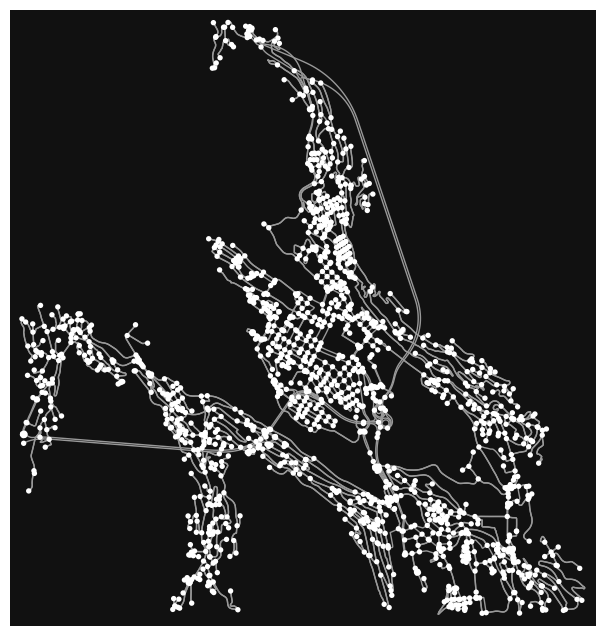

In [6]:
fig, ax = ox.plot_graph(G)

In [7]:
url = "https://nobil.no/api/server/search.php"

params = {
    "apikey": NOBIL_API_KEY,
    "apiversion": "3",
    "action": "search",
    "type": "rectangle",
    "northeast": "(60.42, 5.38)",
    "southwest": "(60.36, 5.26)",
    "limit": "100",
    "format": "json"
}

response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

In [8]:
type(data), len(data)

(dict, 4)

In [9]:
data.keys() if isinstance(data, dict) else None

dict_keys(['Provider', 'Rights', 'apiver', 'chargerstations'])

In [10]:
data

{'Provider': 'NOBIL.no',
 'Rights': 'Creative Commons Attribution 4.0 International License',
 'apiver': '3',
 'chargerstations': [{'csmd': {'id': 75204,
    'name': 'Taxi - Erleveien',
    'ocpidb_mapping_stasjon_id': 'NO#BKK#BAYXQW2SSV9XC',
    'Street': 'Erleveien',
    'House_number': '22',
    'Zipcode': '5097',
    'City': 'BERGEN',
    'Municipality_ID': '4601',
    'Municipality': 'BERGEN',
    'County_ID': '46',
    'County': 'Vestland',
    'Description_of_location': None,
    'Owned_by': 'Eviny',
    'Operator': 'Eviny',
    'Number_charging_points': 8,
    'Position': '(60.361268,5.368839)',
    'Image': 'no.image.svg',
    'User_comment': None,
    'Contact_info': None,
    'Created': '2025-12-23 04:00:09',
    'Updated': '2026-06-26 18:02:16',
    'Station_status': 1,
    'Land_code': 'NOR',
    'International_id': 'NOR_75204'},
   'attr': {'st': {'24': {'attrtypeid': '24',
      'attrname': 'Open 24h',
      'attrvalid': '1',
      'trans': 'Yes',
      'attrval': '1'},


In [18]:
data["chargerstations"][4]["csmd"]

{'id': 69220,
 'name': 'Kilen garasjeanlegg - Frydenbø Eiendom',
 'ocpidb_mapping_stasjon_id': 'NO#KPE#1025',
 'Street': 'Tverrveien',
 'House_number': '7',
 'Zipcode': '5160',
 'City': 'LAKSEVÅG',
 'Municipality_ID': '4601',
 'Municipality': 'BERGEN',
 'County_ID': '46',
 'County': 'Vestland',
 'Description_of_location': None,
 'Owned_by': 'Frydenbø Eiendomsdrift AS',
 'Operator': 'Kople AS',
 'Number_charging_points': 16,
 'Position': '(60.384108,5.311363)',
 'Image': 'no.image.svg',
 'User_comment': None,
 'Contact_info': None,
 'Created': '2025-10-06 10:28:37',
 'Updated': '2026-09-02 19:17:38',
 'Station_status': 1,
 'Land_code': 'NOR',
 'International_id': 'NOR_69220'}

In [16]:
stations = data["chargerstations"]

rows = []

for station in stations:
    csmd = station["csmd"]

    rows.append({
        "id": csmd["id"],
        "name": csmd["name"],
        "street": csmd["Street"],
        "house_number": csmd["House_number"],
        "city": csmd["City"],
        "municipality": csmd["Municipality"],
        "operator": csmd["Operator"],
        "number_charging_points": csmd["Number_charging_points"],
        "position": csmd["Position"],
        "station_status": csmd["Station_status"]
    })

df = pd.DataFrame(rows)

In [17]:
df.head()

,id,name,street,house_number,city,municipality,operator,number_charging_points,position,station_status
0,75204,Taxi - Erleveien,Erleveien,22,BERGEN,BERGEN,Eviny,8,"(60.361268,5.368839)",1
1,14334,Villaveien UiB,Villaveien,10,BERGEN,BERGEN,Fount,4,"(60.38594,5.3241)",1
2,41442,Media City Bergen,"Lars Hilles gate 30, 5008 Bergen, Norge",,BERGEN,BERGEN,Wattif,1,"(60.385467,5.332755)",1
3,78560,SolheimsGarasjen,"Solheimsgaten 29, 5054 Bergen, Norway",,BERGEN,BERGEN,Wattif,18,"(60.375306,5.337727)",1
4,69220,Kilen garasjeanlegg - Frydenbø Eiendom,Tverrveien,7,LAKSEVÅG,BERGEN,Kople AS,16,"(60.384108,5.311363)",1


In [19]:
df[["latitude", "longitude"]] = (
    df["position"]
    .str.strip("()")
    .str.split(",", expand=True)
    .astype(float)
)

df[["name", "latitude", "longitude"]].head()

,name,latitude,longitude
0,Taxi - Erleveien,60.361268,5.368839
1,Villaveien UiB,60.385940,5.324100
2,Media City Bergen,60.385467,5.332755
3,SolheimsGarasjen,60.375306,5.337727
4,Kilen garasjeanlegg - Frydenbø Eiendom,60.384108,5.311363


In [22]:
chargers = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(
        df["longitude"],
        df["latitude"]
    ),
    crs="EPSG:4326"
)

chargers.head()

,id,name,street,house_number,city,municipality,operator,number_charging_points,position,station_status,latitude,longitude,geometry
0,75204,Taxi - Erleveien,Erleveien,22,BERGEN,BERGEN,Eviny,8,"(60.361268,5.368839)",1,60.361268,5.368839,POINT (5.36884 60.36127)
1,14334,Villaveien UiB,Villaveien,10,BERGEN,BERGEN,Fount,4,"(60.38594,5.3241)",1,60.385940,5.324100,POINT (5.3241 60.38594)
2,41442,Media City Bergen,"Lars Hilles gate 30, 5008 Bergen, Norge",,BERGEN,BERGEN,Wattif,1,"(60.385467,5.332755)",1,60.385467,5.332755,POINT (5.33276 60.38547)
3,78560,SolheimsGarasjen,"Solheimsgaten 29, 5054 Bergen, Norway",,BERGEN,BERGEN,Wattif,18,"(60.375306,5.337727)",1,60.375306,5.337727,POINT (5.33773 60.37531)
4,69220,Kilen garasjeanlegg - Frydenbø Eiendom,Tverrveien,7,LAKSEVÅG,BERGEN,Kople AS,16,"(60.384108,5.311363)",1,60.384108,5.311363,POINT (5.31136 60.38411)


In [26]:
# Remove stations that are not active
chargers = chargers[
    chargers["station_status"] == 1
].copy()

len(chargers)

75

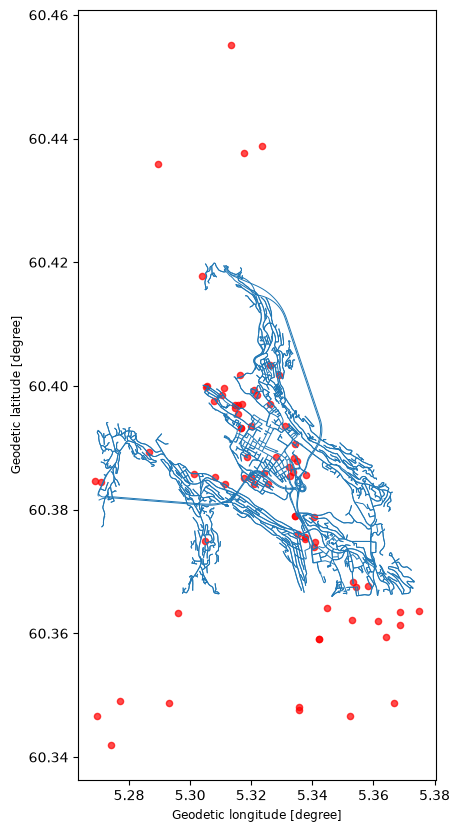

In [29]:
nodes, edges = ox.graph_to_gdfs(G)

fig, ax = plt.subplots(figsize=(10, 10))

edges.plot(
    ax=ax,
    linewidth=0.7
)

chargers.plot(
    ax=ax,
    markersize=20,
    color="red",
    alpha=0.7
)

plt.show()